## Setup

In [2]:
import os
import re
import numpy as np
import matplotlib.pyplot as plt

In [1]:
from google.colab import drive
drive.mount('/content/drive')

base_dir = "/content/drive/MyDrive/Lucas"

Mounted at /content/drive


## Carregando os attention scores

In [3]:
wsi_txt = base_dir + "/attention_scores.txt"
nil_txt = base_dir + "/nil_attention_scores.txt"

wsi_attention = []
nil_attention = []
nil_row = []
with open(wsi_txt, "r", encoding="utf-8") as f:
    for linha in f:
        score = re.search(r"-?\d+\.\d+",linha.strip())
        if score:
          wsi_attention.append(float(score.group()))

with open(nil_txt, "r", encoding="utf-8") as f:
    for linha in f:
        score = re.search(r"-?\d+\.\d+",linha.strip())
        if score:
          nil_row.append(float(score.group()))
        else:
          nil_attention.append(nil_row)
          nil_row = []

In [ ]:
print(f"wsi_attention length: {len(wsi_attention)}")
print(f"nil_attention length: {len(nil_attention)}")

wsi_attention length: 8798
nil_attention length: 200


## Histogramas dos attention scores

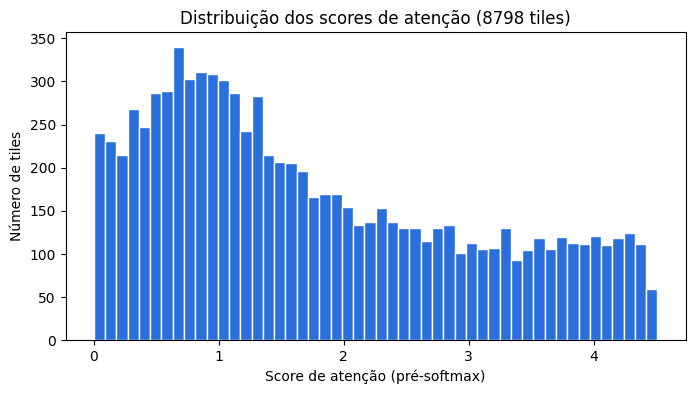

In [ ]:
plt.figure(figsize=(8, 4))
plt.hist(wsi_attention, bins=50, color="#2a6fdb", edgecolor="white")
plt.xlabel("Score de atenção (pré-softmax)")
plt.ylabel("Número de tiles")
plt.title(f"Distribuição dos scores de atenção ({len(wsi_attention)} tiles)")
plt.show()

In [ ]:
def plot_grid(start, rows=5, cols=4):
    fig, axes = plt.subplots(rows, cols, figsize=(16, 15))
    for ax, i in zip(axes.flat, range(start, start + rows * cols)):
        scores = np.array([float(s) for s in nil_attention[i]])
        ax.hist(scores, bins=50, color="#2a6fdb", edgecolor="white")
        ax.set_title(f"NIL {i + 1} ({len(scores)} tiles)", fontsize=10)
    for ax in axes[-1]:
        ax.set_xlabel("Score de atenção (pré-softmax)")
    for ax in axes[:, 0]:
        ax.set_ylabel("Número de tiles")
    plt.tight_layout()
    plt.show()

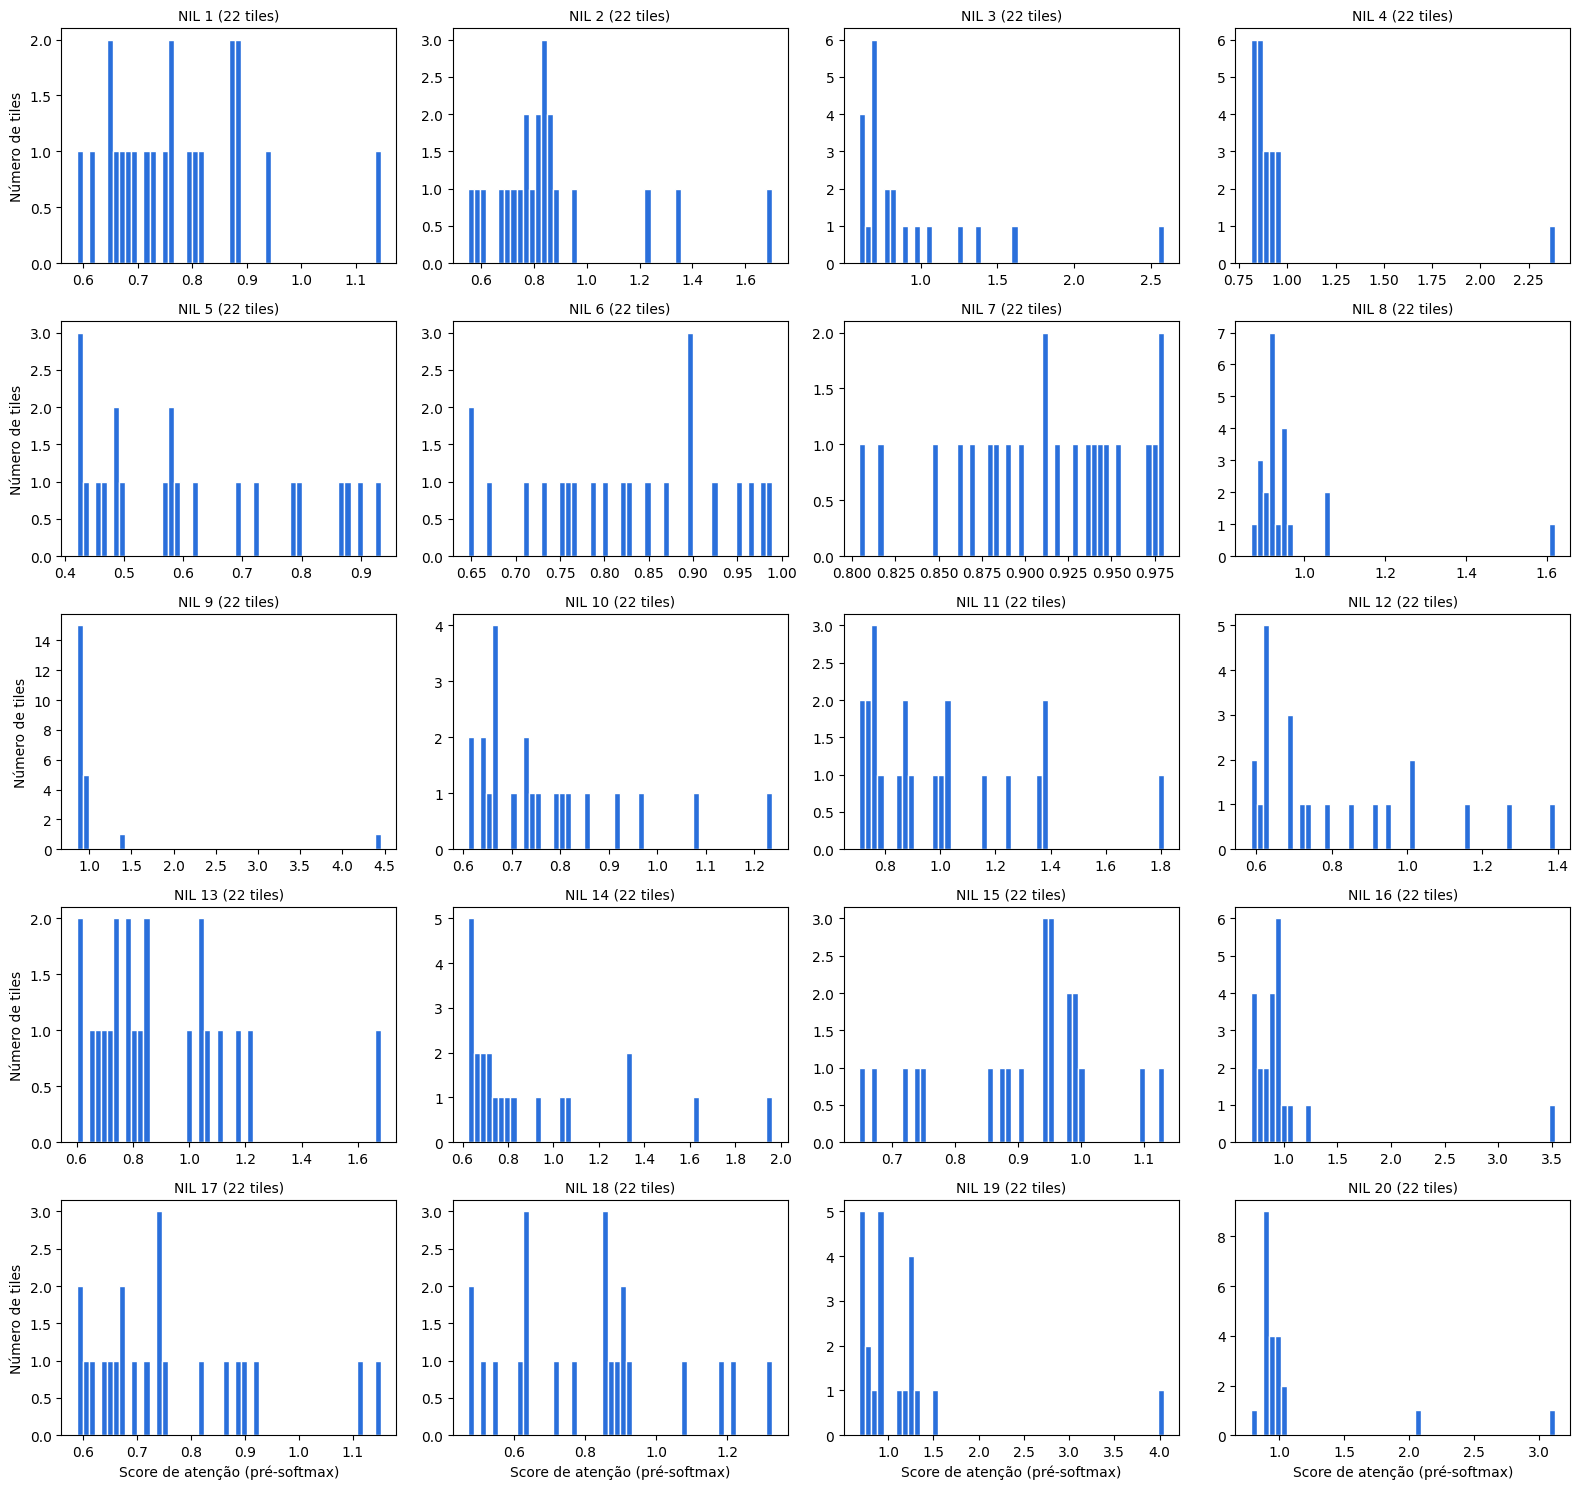

In [ ]:
plot_grid(0)

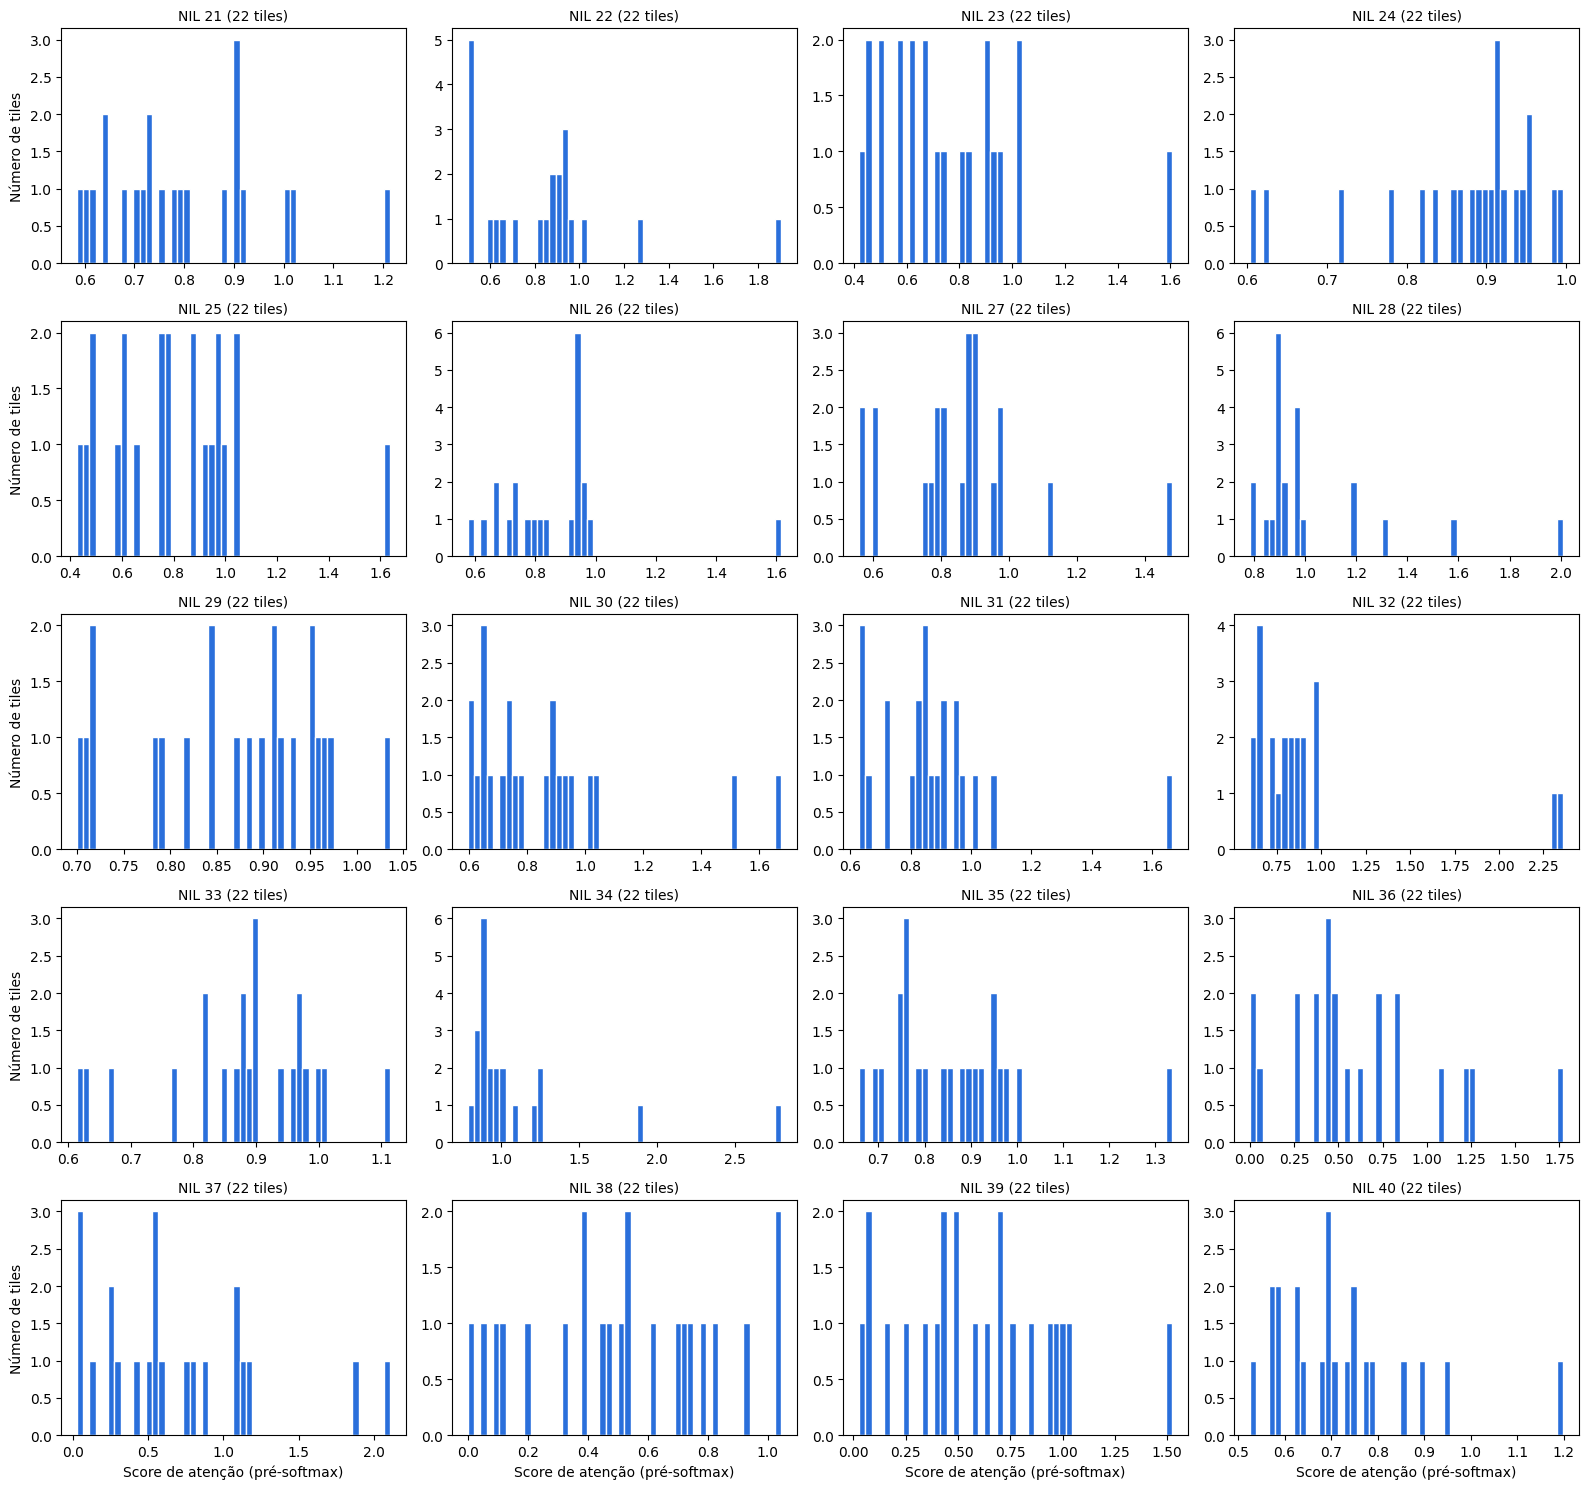

In [ ]:
plot_grid(20)

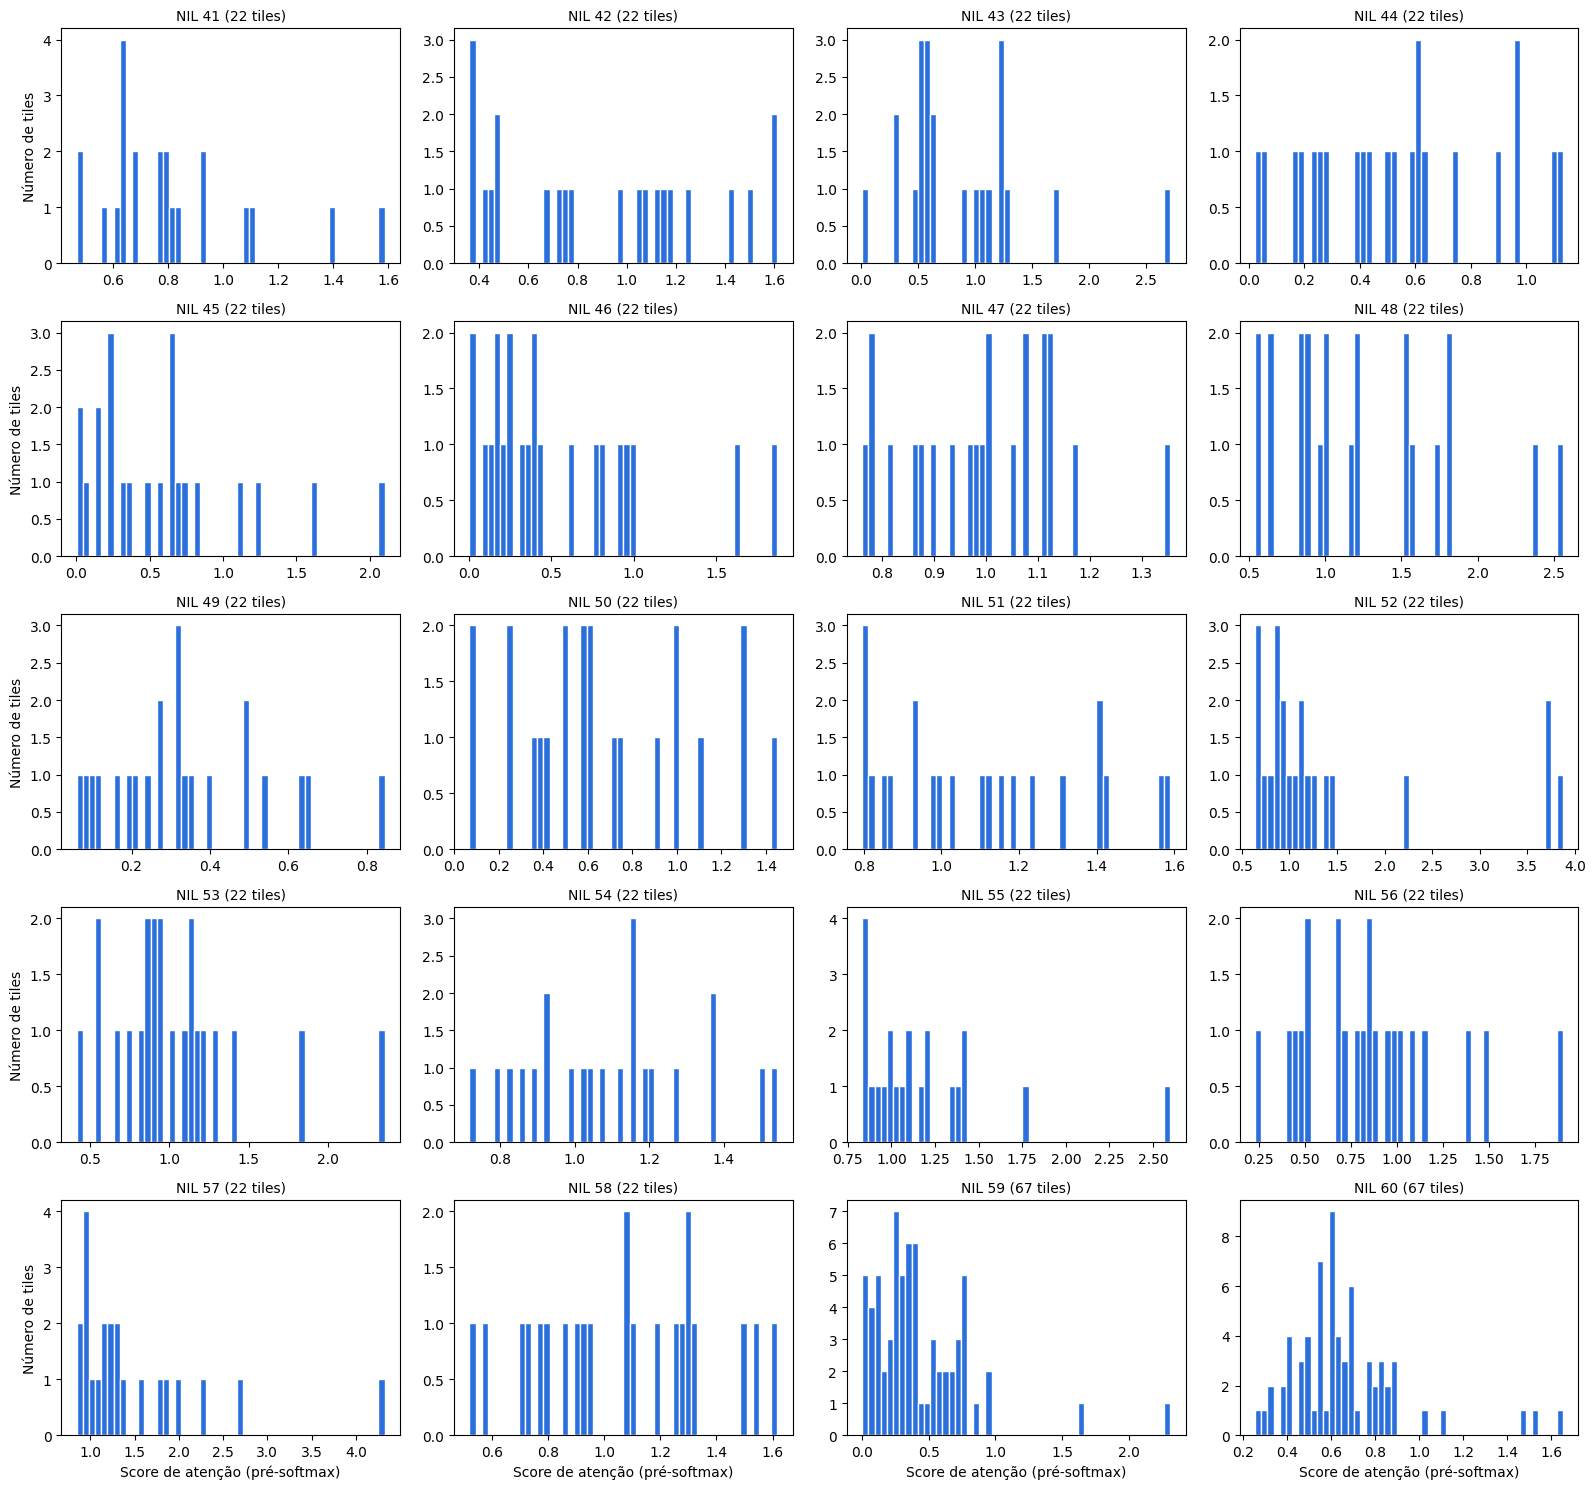

In [ ]:
plot_grid(40)

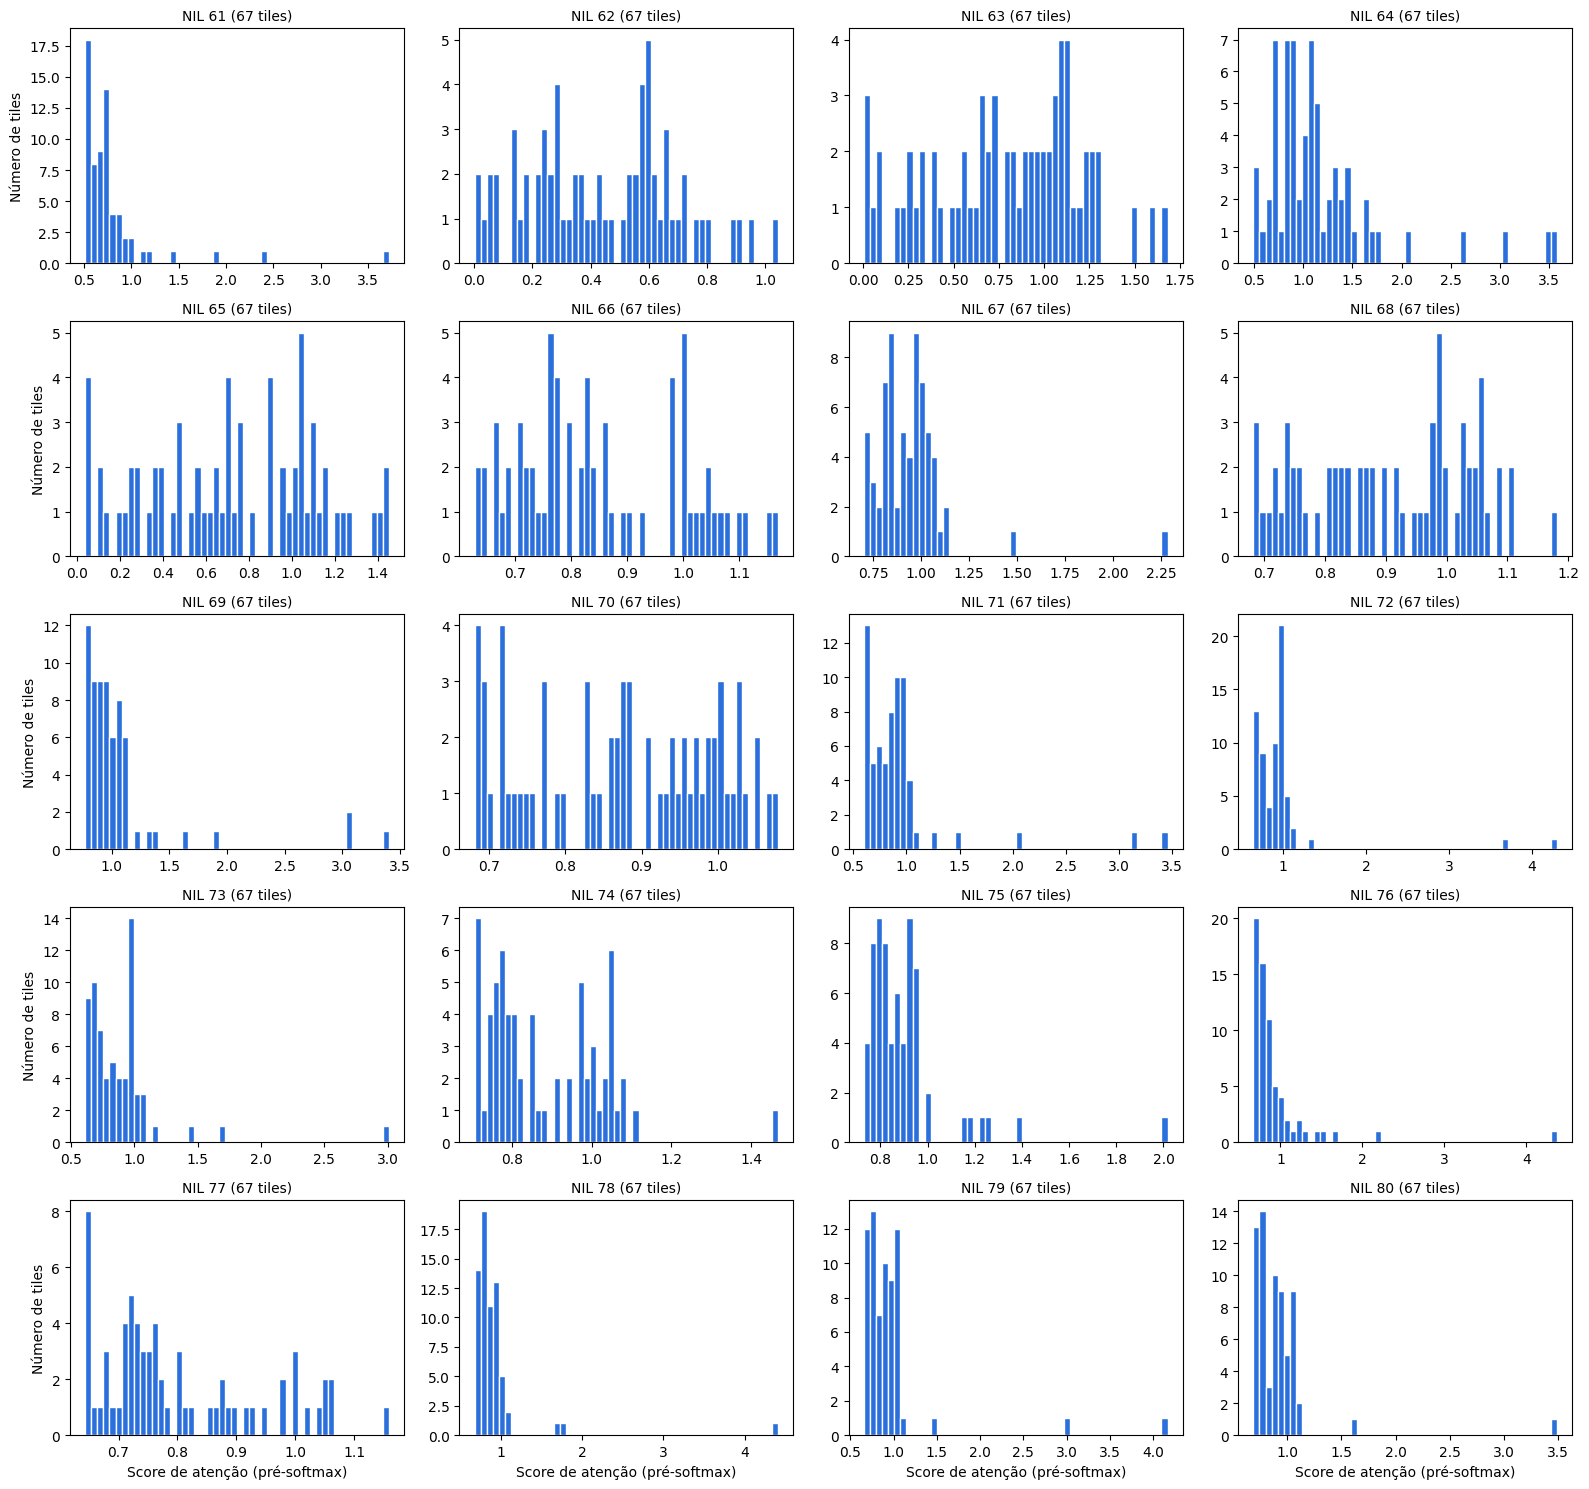

In [ ]:
plot_grid(60)

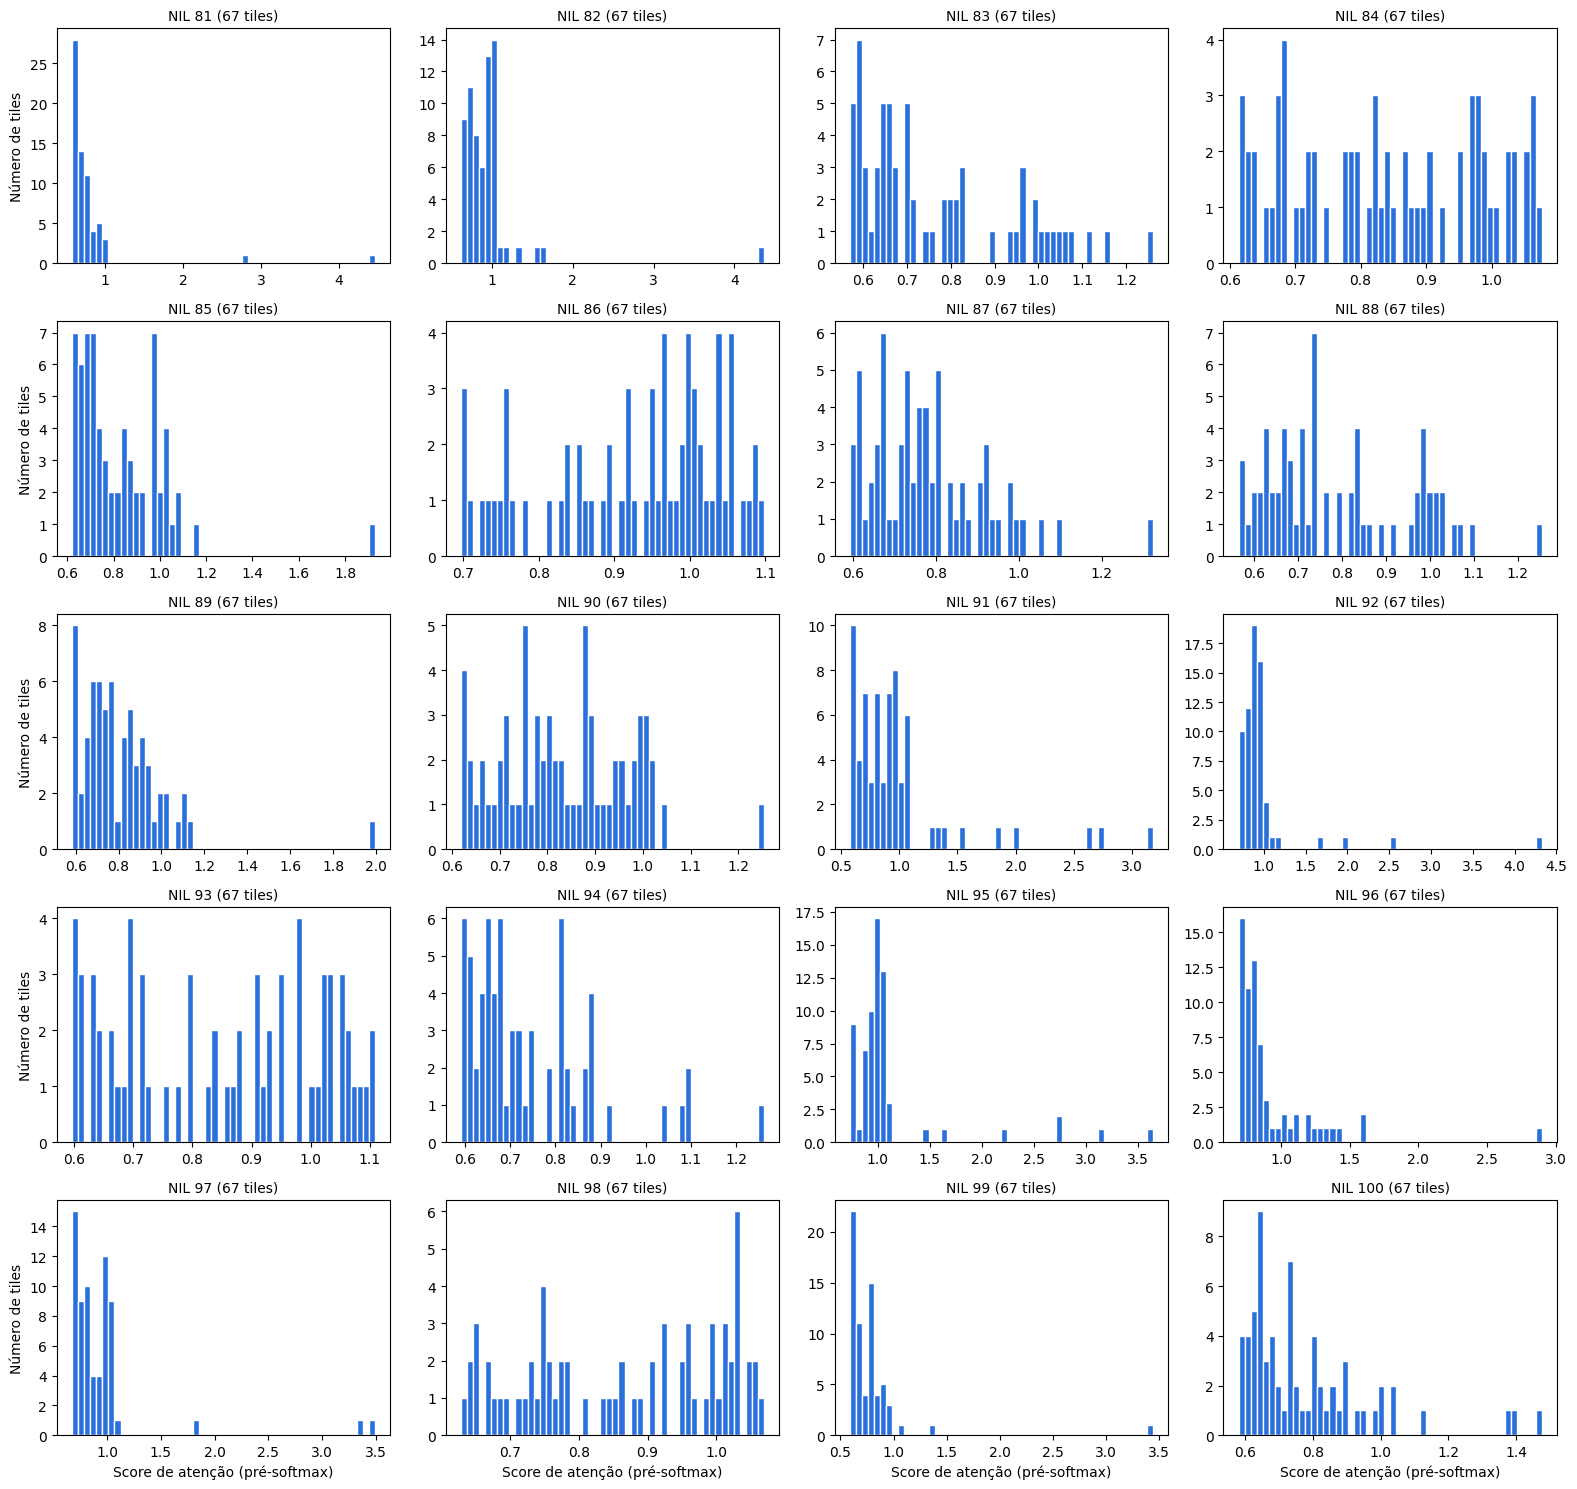

In [ ]:
plot_grid(80)

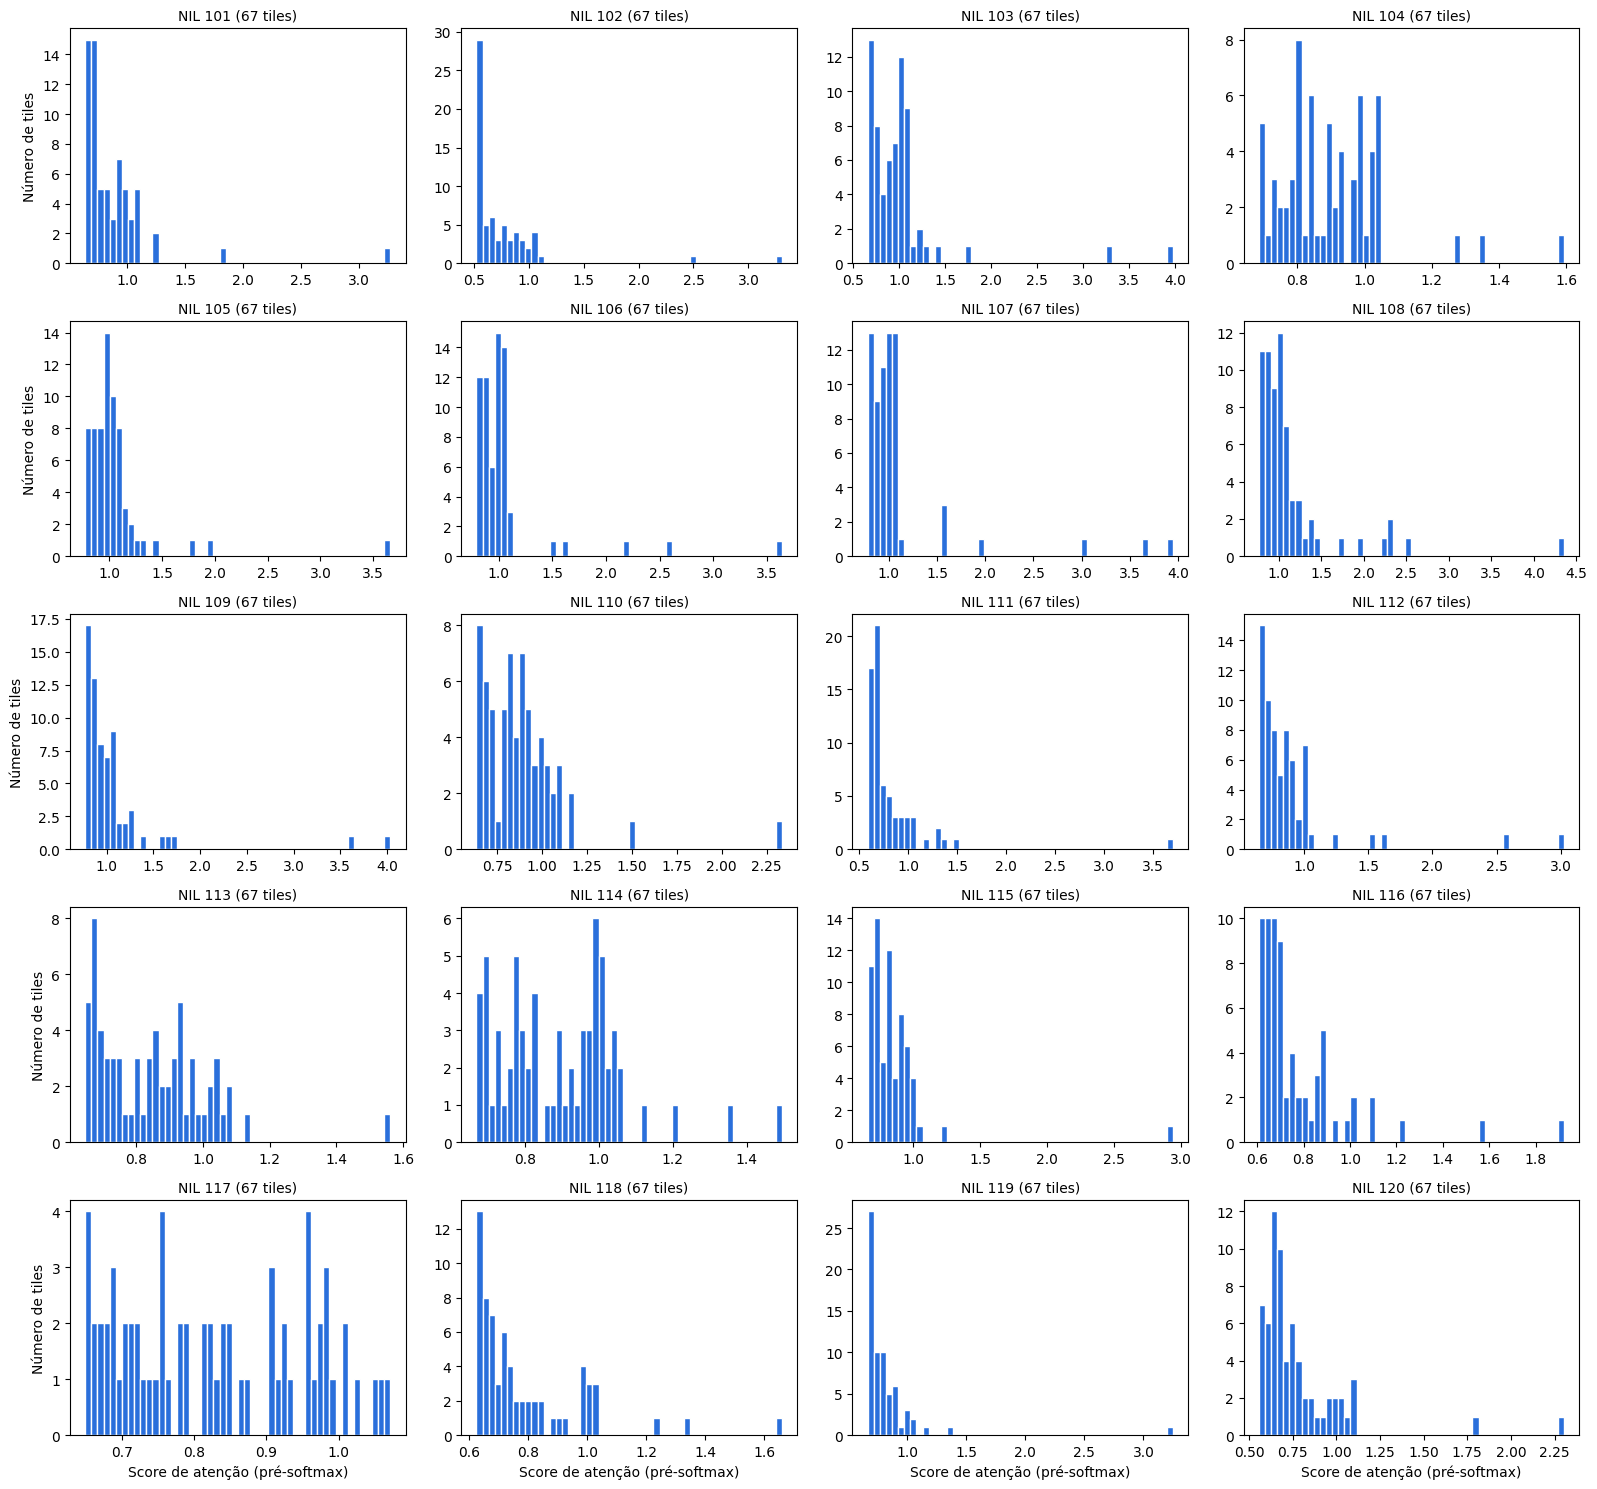

In [ ]:
plot_grid(100)

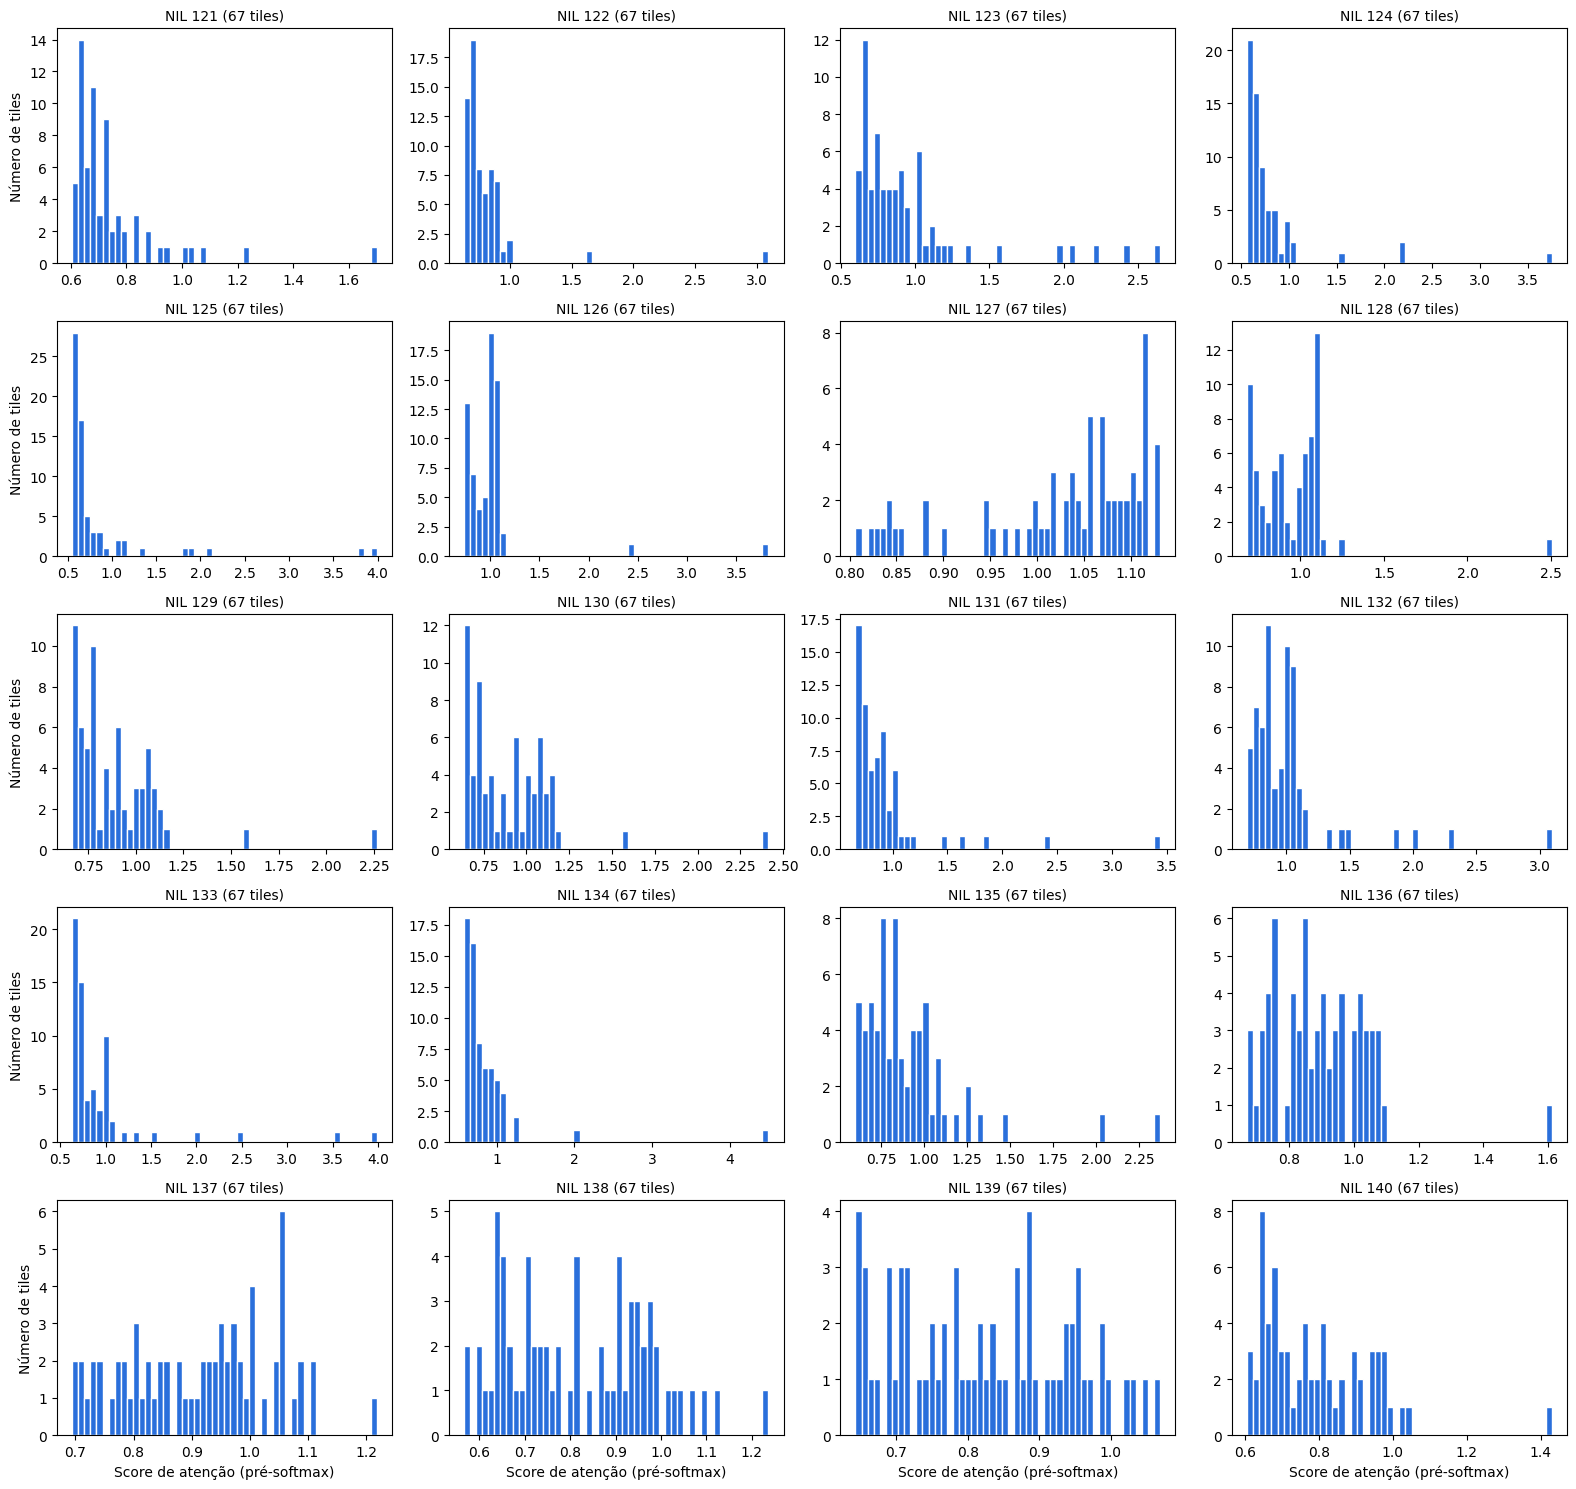

In [ ]:
plot_grid(120)

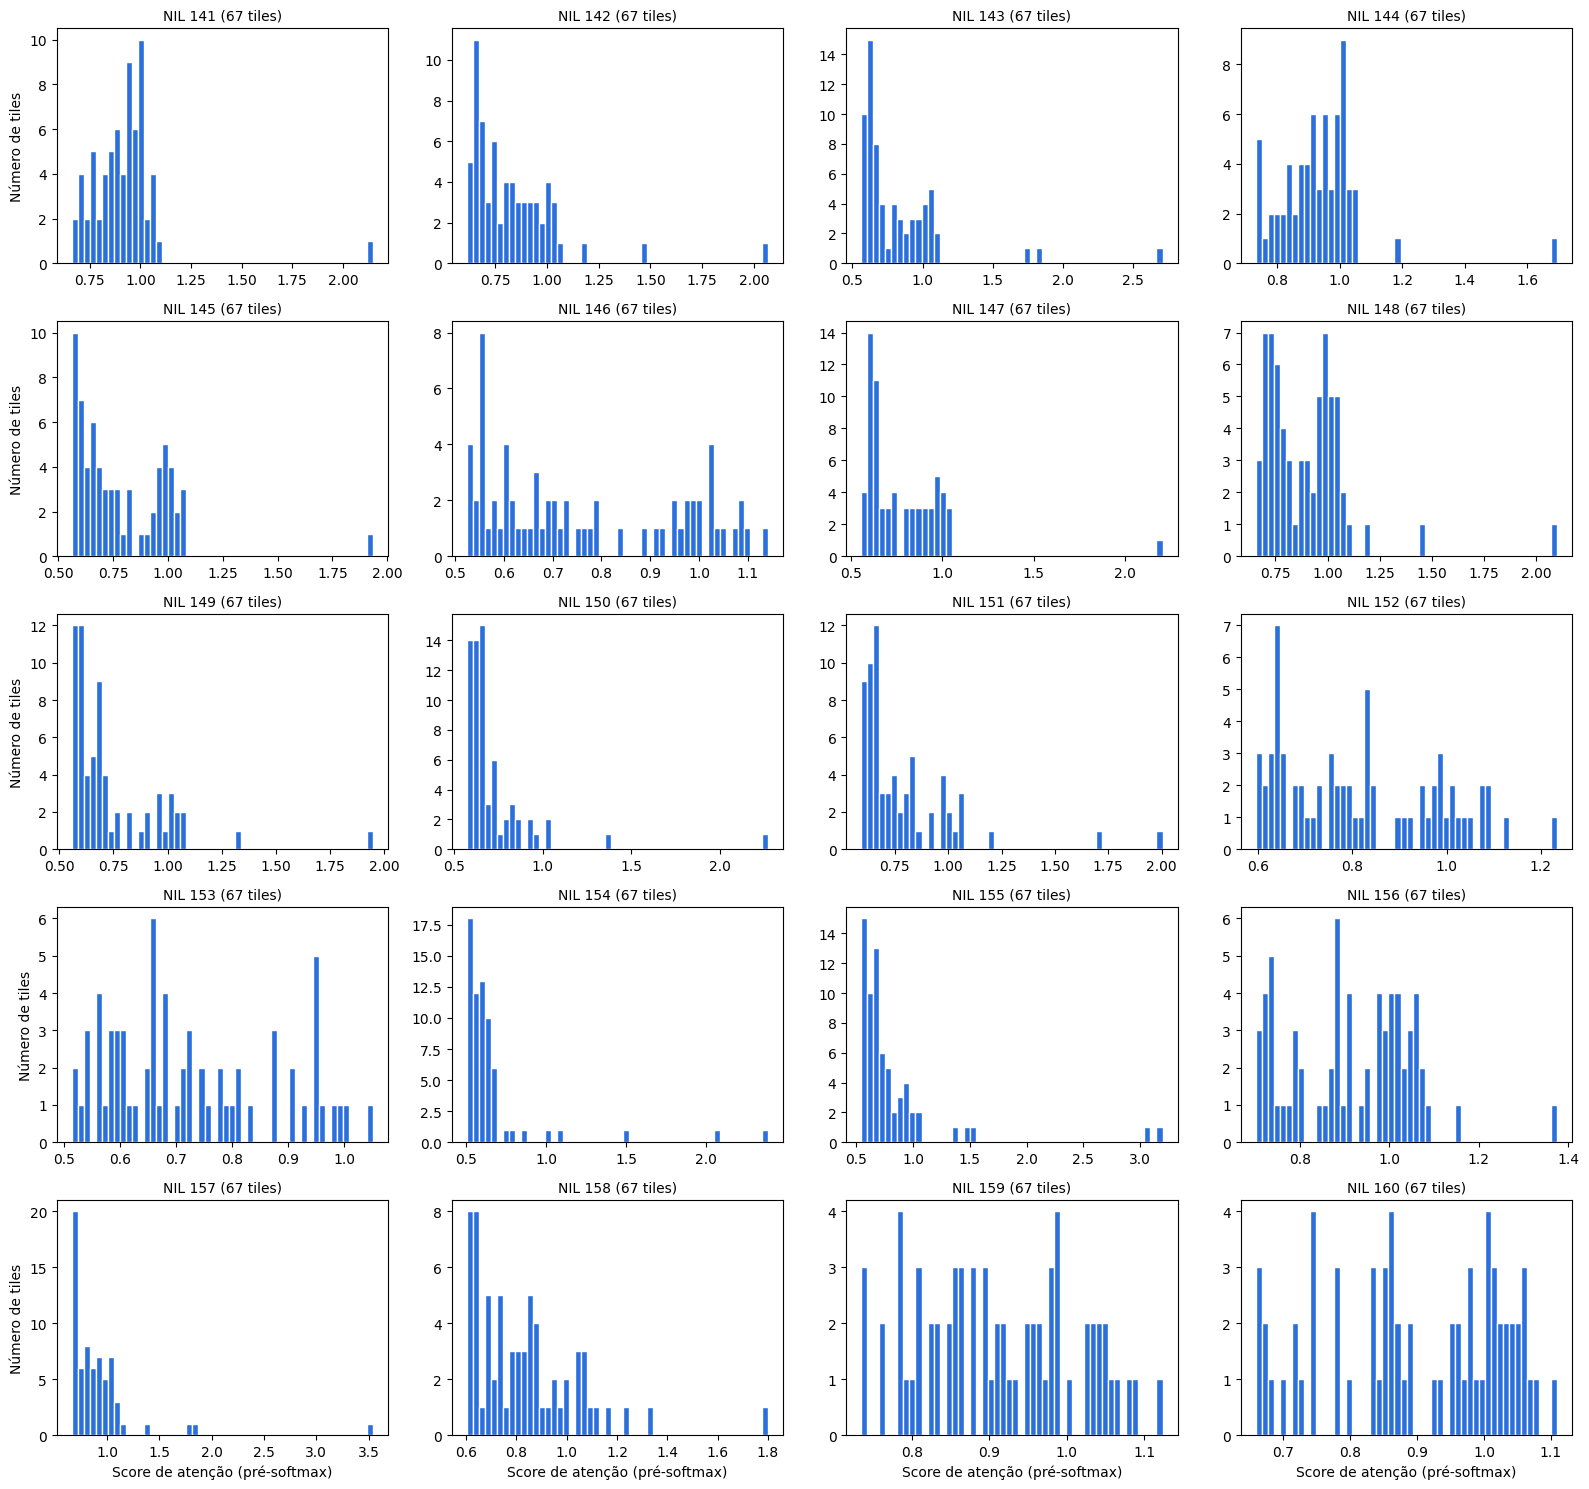

In [ ]:
plot_grid(140)

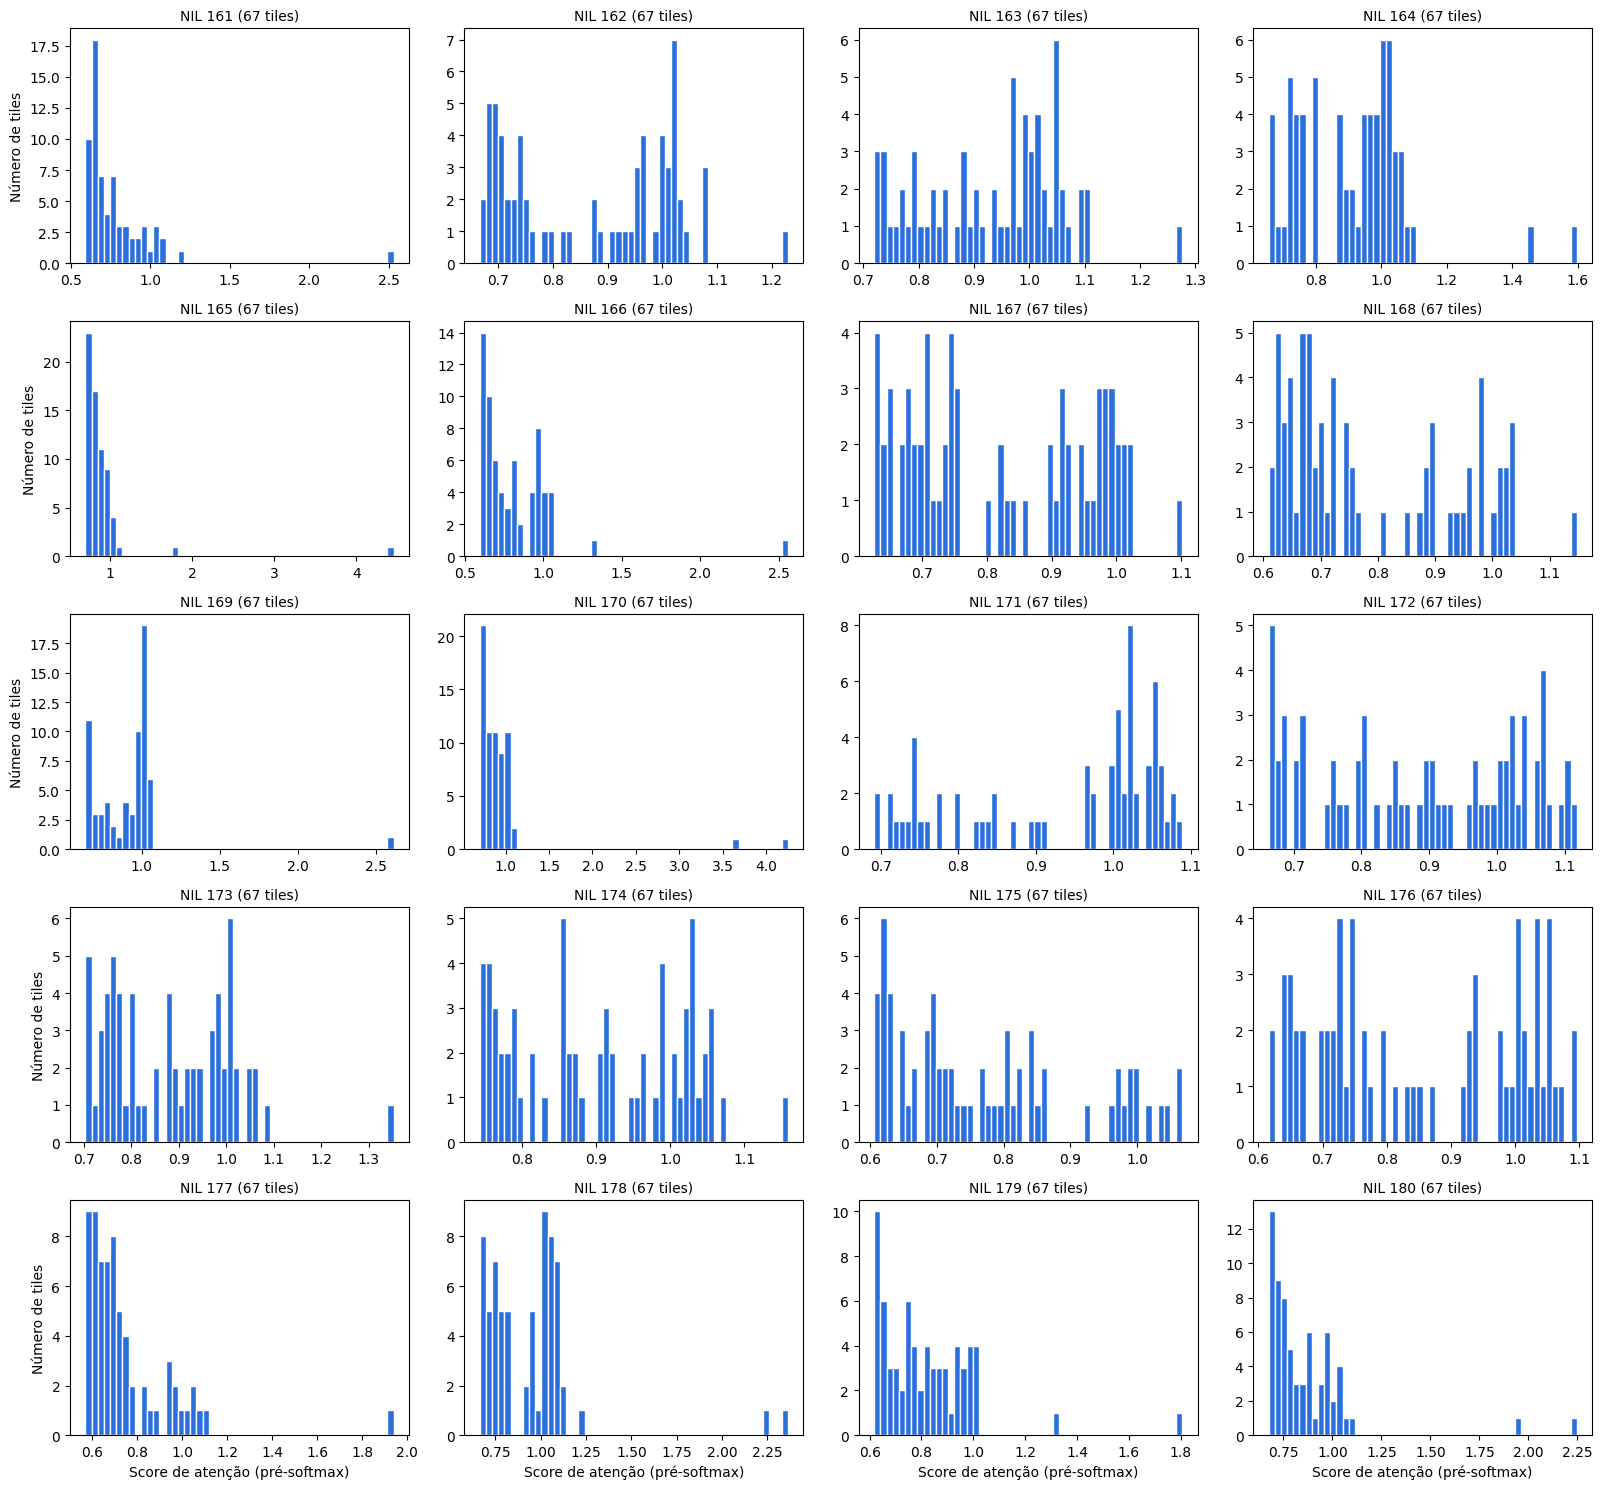

In [ ]:
plot_grid(160)

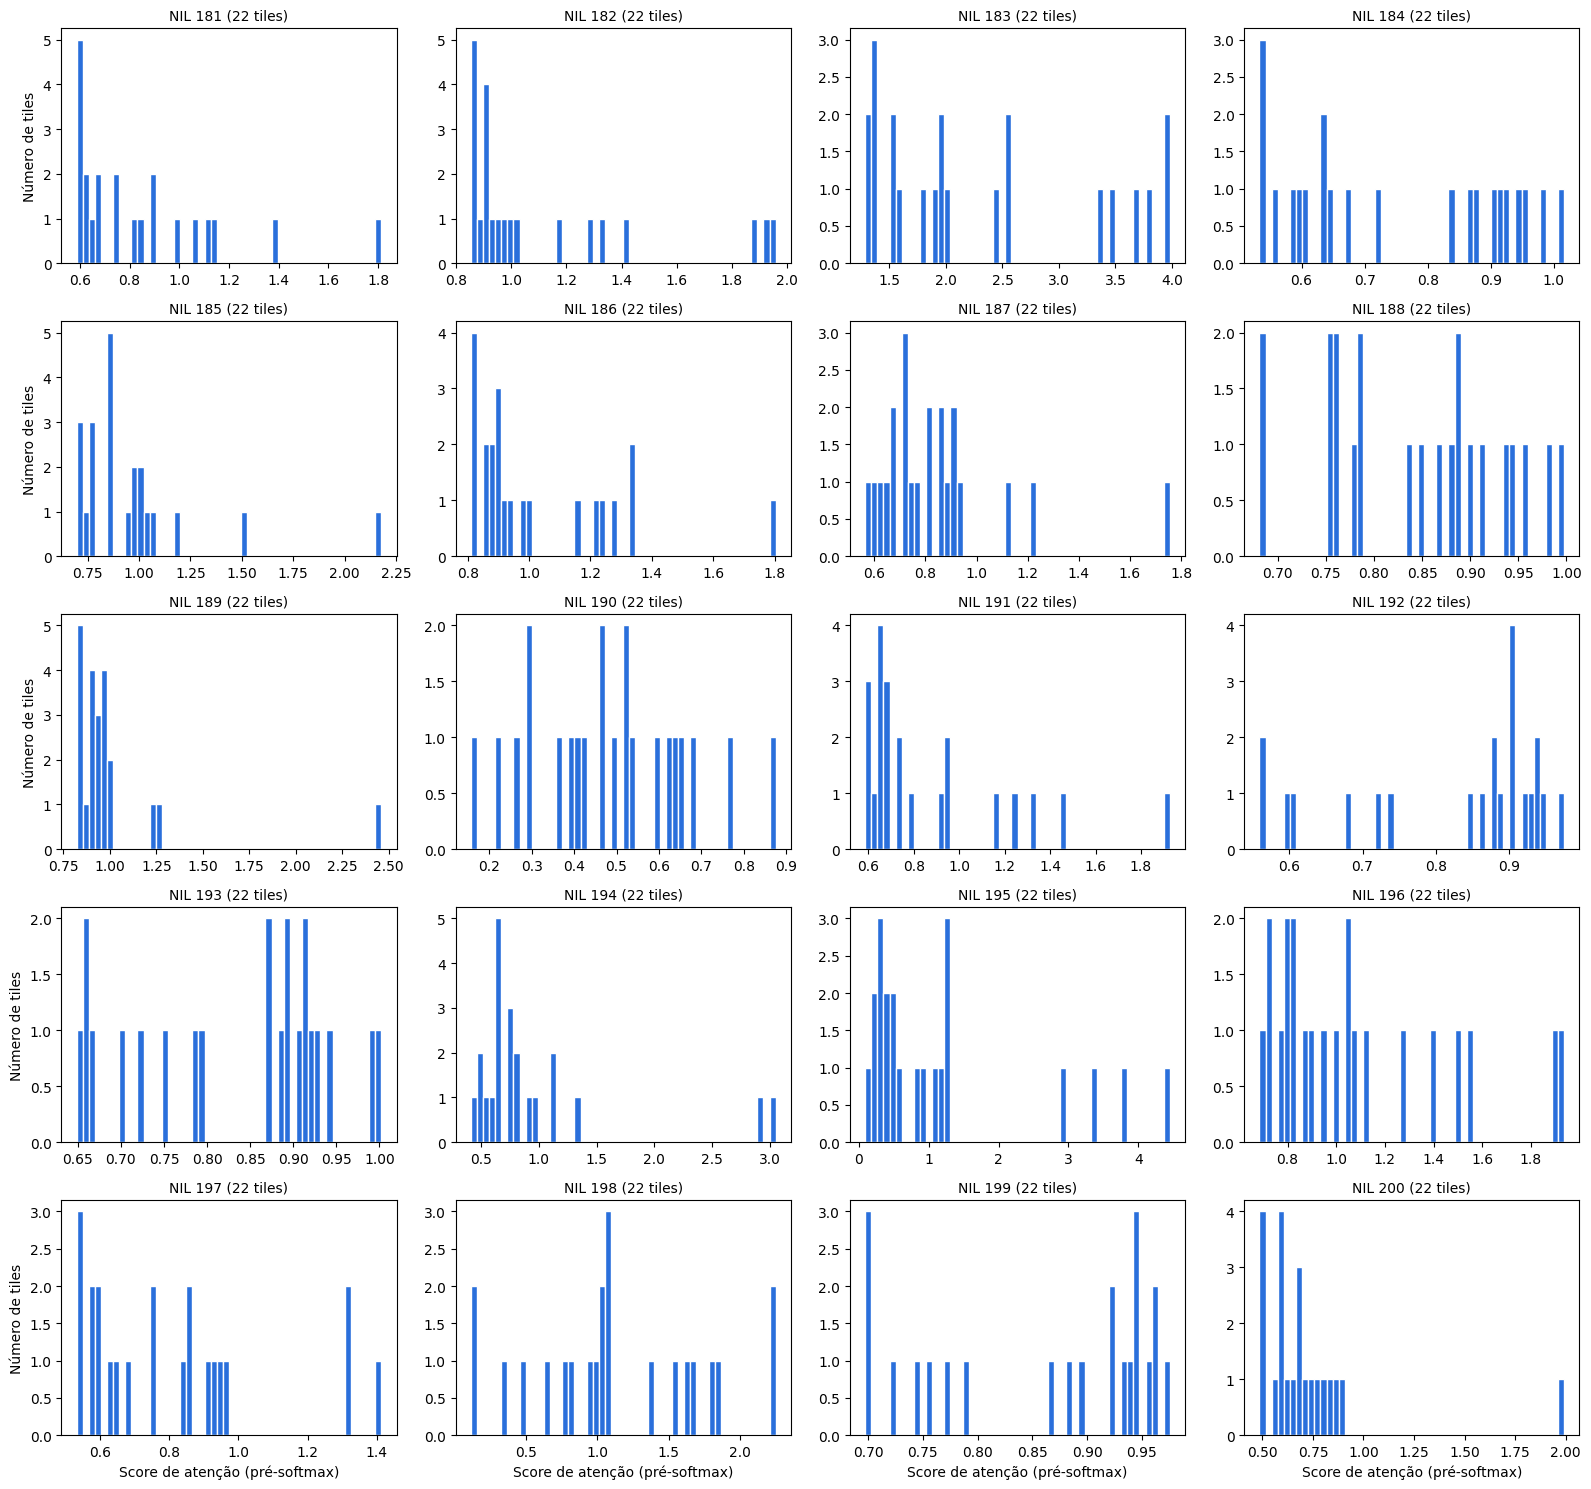

In [ ]:
plot_grid(180)

## Distribuição dos attention scores

In [4]:
def faixas(scores):
  scores = np.array(scores)
  for a in range(int(np.floor(scores.min())), int(np.ceil(scores.max()))):
      mask = (scores >= a) & (scores < a + 1)
      n = mask.sum()
      if n == 0:
        continue
      pct = n / len(scores) * 100
      print(f"{a} <= x < {a + 1}: {pct:8.1f}% ({n} tiles)")

In [5]:
print("WSI")
faixas(wsi_attention)

for i in range(0,200,20):
    print(f"\nNIL {i}")
    faixas(nil_attention[i])

WSI
-1 <= x < 0:      4.6% (408 tiles)
0 <= x < 1:     30.3% (2664 tiles)
1 <= x < 2:     27.7% (2433 tiles)
2 <= x < 3:     16.5% (1455 tiles)
3 <= x < 4:     14.1% (1239 tiles)
4 <= x < 5:      6.8% (599 tiles)

NIL 0
0 <= x < 1:     95.5% (21 tiles)
1 <= x < 2:      4.5% (1 tiles)

NIL 20
0 <= x < 1:     86.4% (19 tiles)
1 <= x < 2:     13.6% (3 tiles)

NIL 40
0 <= x < 1:     81.8% (18 tiles)
1 <= x < 2:     18.2% (4 tiles)

NIL 60
0 <= x < 1:     91.0% (61 tiles)
1 <= x < 2:      6.0% (4 tiles)
2 <= x < 3:      1.5% (1 tiles)
3 <= x < 4:      1.5% (1 tiles)

NIL 80
0 <= x < 1:     97.0% (65 tiles)
2 <= x < 3:      1.5% (1 tiles)
4 <= x < 5:      1.5% (1 tiles)

NIL 100
0 <= x < 1:     82.1% (55 tiles)
1 <= x < 2:     16.4% (11 tiles)
3 <= x < 4:      1.5% (1 tiles)

NIL 120
0 <= x < 1:     92.5% (62 tiles)
1 <= x < 2:      7.5% (5 tiles)

NIL 140
0 <= x < 1:     79.1% (53 tiles)
1 <= x < 2:     19.4% (13 tiles)
2 <= x < 3:      1.5% (1 tiles)

NIL 160
0 <= x < 1:     88.1% (59 tile